# Phase 2b · Which alteration set gives the better gene-pair list?

Notebook 02 builds the gene-pair list three times, with the same test, on the same patients -- only the definition
of "altered" differs:

| Set | A gene counts as altered if it has ... |
|---|---|
| **SNV** | a likely-harmful mutation (incl. TERT promoter and MET exon 14) |
| **SNV+CNV** | a mutation **or** a deep copy-number change -- **the main table** |
| **SNV+CNV+SV** | a mutation, a deep copy-number change **or** a driver fusion |

Each set is judged three ways:

| Part | Question | Data |
|---|---|---|
| 1 | **Known biology:** how many published gene pairs does it find? | 58 pairs from the literature (`data/curated/textbook_pairs.csv`) |
| 2 | **Precision and recall:** are its calls real, and how many real links does it find? | real data with links of known strength planted |
| 3 | **Independent patients:** do its candidates hold up in TCGA? | TCGA PanCancer Atlas |

How our test compares with other methods (Fisher, DISCOVER-style, SELECT) is in notebook 02c, Section G.

In [1]:
import numpy as np
import pandas as pd

P = "../data/processed/"
C = "../data/curated/"
pd.set_option("display.width", 160)
SETS = {"SNV": "comutation_pairs_snv.parquet", "SNV+CNV": "comutation_pairs.parquet",
        "SNV+CNV+SV": "comutation_pairs_snv_cnv_sv.parquet"}
pairs = {n: pd.read_parquet(P + f) for n, f in SETS.items()}
v = pd.read_parquet(P + "alteration_set_validation.parquet")      # scripts/analyses/23_alteration_set_validation.py
pd.DataFrame({n: {"pairs tested": len(p), "interaction candidates": int(p.interaction_candidate.sum())}
              for n, p in pairs.items()})

,SNV,SNV+CNV,SNV+CNV+SV
pairs tested,2174,6809,6871
interaction candidates,466,1569,1609


---
## 1 · Known biology: how many published pairs does each set find?

58 gene pairs with a published direction (15 co-occurring, 43 exclusive), each with a reference and DOI, chosen
**before** looking at the results. They cover mutations, copy-number changes and fusions in 17 cancer types -- e.g.
*EGFR* vs *KRAS* and *ALK* fusion vs *EGFR* in lung cancer, *MDM2* amplification vs *TP53* in glioma, *SF3B1* vs
*SRSF2* in myelodysplasia. A pair is **found** if it is an interaction candidate in the published direction;
otherwise the reason is given.

In [2]:
tb = pd.read_csv(C + "textbook_pairs.csv")


def verdict(p, r):
    m = p[(p.Cancer_Type == r.Cancer_Type) & (((p.Gene_A == r.Gene_A) & (p.Gene_B == r.Gene_B))
                                             | ((p.Gene_A == r.Gene_B) & (p.Gene_B == r.Gene_A)))]
    if m.empty: return "not tested"
    m = m.iloc[0]
    if m.q_value >= .05: return "not significant"
    if m.direction != r.expected_direction: return "opposite direction"
    if not m.interaction_candidate: return "removed: one DNA event"
    return "found"


known = tb[["Cancer_Type", "Gene_A", "Gene_B", "expected_direction", "reference"]].copy()
for n, p in pairs.items():
    known[n] = [verdict(p, r) for r in tb.itertuples()]
pd.DataFrame({n: known[n].value_counts() for n in pairs}).fillna(0).astype(int)

,SNV,SNV+CNV,SNV+CNV+SV
found,35,44,50
not significant,7,6,6
not tested,16,7,1
removed: one DNA event,0,1,1


Only the pairs that some set does not find:

In [3]:
known[known[list(pairs)].ne("found").any(axis=1)].drop(columns="reference")

,Cancer_Type,Gene_A,Gene_B,expected_direction,SNV,SNV+CNV,SNV+CNV+SV
5,Non-Small Cell Lung Cancer,EGFR,ERBB2,exclusive,not tested,found,found
10,Breast Cancer,PIK3CA,PTEN,exclusive,not significant,found,found
13,Colorectal Cancer,BRAF,NRAS,exclusive,not significant,not significant,not significant
18,Glioma,CDKN2A,EGFR,co-occurring,not tested,found,found
19,Glioma,MDM2,TP53,exclusive,not tested,found,found
20,Glioma,CDK4,CDKN2A,exclusive,not tested,found,found
21,Endometrial Cancer,PIK3CA,PTEN,co-occurring,not significant,not significant,not significant
26,Bladder Cancer,MDM2,TP53,exclusive,not tested,found,found
27,Esophagogastric Cancer,ERBB2,KRAS,exclusive,not significant,found,found
29,Non-Small Cell Lung Cancer,ALK_fusion,EGFR,exclusive,not tested,not tested,found


> **Reading.** Adding alteration types finds more known biology: **35 of 58** pairs with mutations only, **44** with
> copy number, **50** with fusions. Most of the difference is pairs a set cannot see at all ("not tested"): copy-number
> pairs (*MDM2* vs *TP53*, *CCNE1* vs *BRCA1/2*, *ERBB2* vs *FGFR2*) need copy number, fusion pairs (*ALK* vs *EGFR*,
> *ERG* vs *SPOP*, *BRAF* vs *RET*) need fusions. No set finds a pair in the opposite direction.
>
> Two misses are worth knowing: *KIT* vs *PDGFRA* in GIST is found by SNV but removed once copy number is added -- the
> two genes are neighbours on 4q12, so the one-DNA-event rule treats them as one amplicon; and a few pairs are tested
> but not significant in every set (*BRAF* vs *NRAS* in colorectal cancer, *SF3B1* vs *SRSF2*, *RHOA* + *TET2*) -- the
> recall cost of a strict test (Part 2).

---
## 2 · Precision and recall where the truth is known

On real data nobody knows every true link, so precision and recall are measured on data where the answer is known:
each set's own real data (9 large cancer types), **shuffled within subtypes** so that every patient keeps its number of
alterations and every gene its frequency but no gene-gene link survives, then **~215 links of known strength
planted** (co-occurring or exclusive, 1.5x to 3x; 6 replicates). A planted link is **found** if called (q < 0.05) in
the right direction; every other call is wrong. The same shuffled data without planted links shows how often a set
calls something that is not there.

In [4]:
rows = []
for n in SETS:
    nl = v[(v.alteration_set == n) & (v.check == "no links")]
    s = v[(v.alteration_set == n) & (v.check == "planted links")]
    call = s.q < .05; hit = call & (s.truth != "none") & (s.direction == s.truth)
    rows.append({"alteration set": n, "no links: called (q < 0.05)": (nl.q < .05).mean(),
                 "planted links": int((s.truth != "none").sum()), "calls": int(call.sum()),
                 "precision": hit.sum() / max(call.sum(), 1), "recall": hit.sum() / (s.truth != "none").sum()})
pd.DataFrame(rows).set_index("alteration set").round(3)

,no links: called (q < 0.05),planted links,calls,precision,recall
alteration set,,,,,
SNV,0.0,215,111,0.955,0.493
SNV+CNV,0.0,216,104,0.962,0.463
SNV+CNV+SV,0.0,216,112,0.982,0.509


Recall by the strength of the planted link:

In [5]:
s = v[(v.check == "planted links") & (v.truth != "none")]
s.assign(found=(s.q < .05) & (s.direction == s.truth)).groupby(["truth", "fold", "alteration_set"]).found.mean() \
 .unstack().round(2)

alteration_set      SNV  SNV+CNV  SNV+CNV+SV
truth        fold                           
co-occurring 1.5   0.22     0.19        0.39
             2.0   0.69     0.64        0.58
             3.0   0.92     0.89        0.89
exclusive    1.5   0.19     0.14        0.14
             2.0   0.42     0.39        0.42
             3.0   0.51     0.53        0.64

> **Reading.** The test is **equally precise on every set**: nothing is called on data without links, and 95-98% of
> calls on planted data are real. Recall is 46-51% -- strong links are found, weak ones (1.5x) mostly not. Adding copy
> number or fusions does not make the list less trustworthy.

---
## 3 · Independent patients: TCGA

Each set's candidates re-tested with the same test in TCGA (whole exome, other centres, non-hypermutated patients;
mutations only for the SNV set). TCGA has about 1/20 of GENIE's patients, so **direction** is the main measure.
**Control** = pairs *not* significant in GENIE: how much agreement to expect without a real link. TCGA has no fusion
calls, so fusion pairs cannot be tested there.

In [6]:
rows = []
for n in SETS:
    t = v[(v.alteration_set == n) & (v.check == "TCGA")]
    for grp, sel in [("candidates", t.interaction_candidate == True), ("control: not significant", t.q_value >= .05)]:
        d = t[sel]; same = d.tcga_direction == d.direction
        rows.append({"alteration set": n, "group": grp, "testable in TCGA": len(d), "same direction": round(same.mean(), 3),
                     "significant, same direction": round(((d.tcga_p < .05) & same).mean(), 3),
                     "significant, opposite": int(((d.tcga_p < .05) & ~same).sum())})
pd.DataFrame(rows).set_index(["alteration set", "group"])

testable in TCGA  same direction  significant, same direction  significant, opposite
alteration set group                                                                                                         
SNV            candidates                             163           0.933                        0.466                      0
               control: not significant               191           0.707                        0.079                      5
SNV+CNV        candidates                             759           0.884                        0.325                      0
               control: not significant              1322           0.691                        0.075                     12
SNV+CNV+SV     candidates                             762           0.882                        0.324                      0
               control: not significant              1319           0.691                        0.074                     13

> **Reading.** Candidates of every set keep their direction in TCGA far more often than control pairs, and none is
> significant the other way. SNV candidates hold up best (93% vs 88% once copy number is added) -- mutations are
> called more consistently than copy number between cohorts -- but the SNV set has a fifth as many candidates.

---
### Figure -- Phase 2b at a glance
**a** published pairs found by each set, or why not · **b** precision and recall on data with planted links ·
**c** candidates keeping their direction in TCGA, against control pairs.  \n*Drawn by `scripts/figures/phase2b_validation.R`
-> `results/figures/phase2b_validation/figure_phase2b.pdf`*

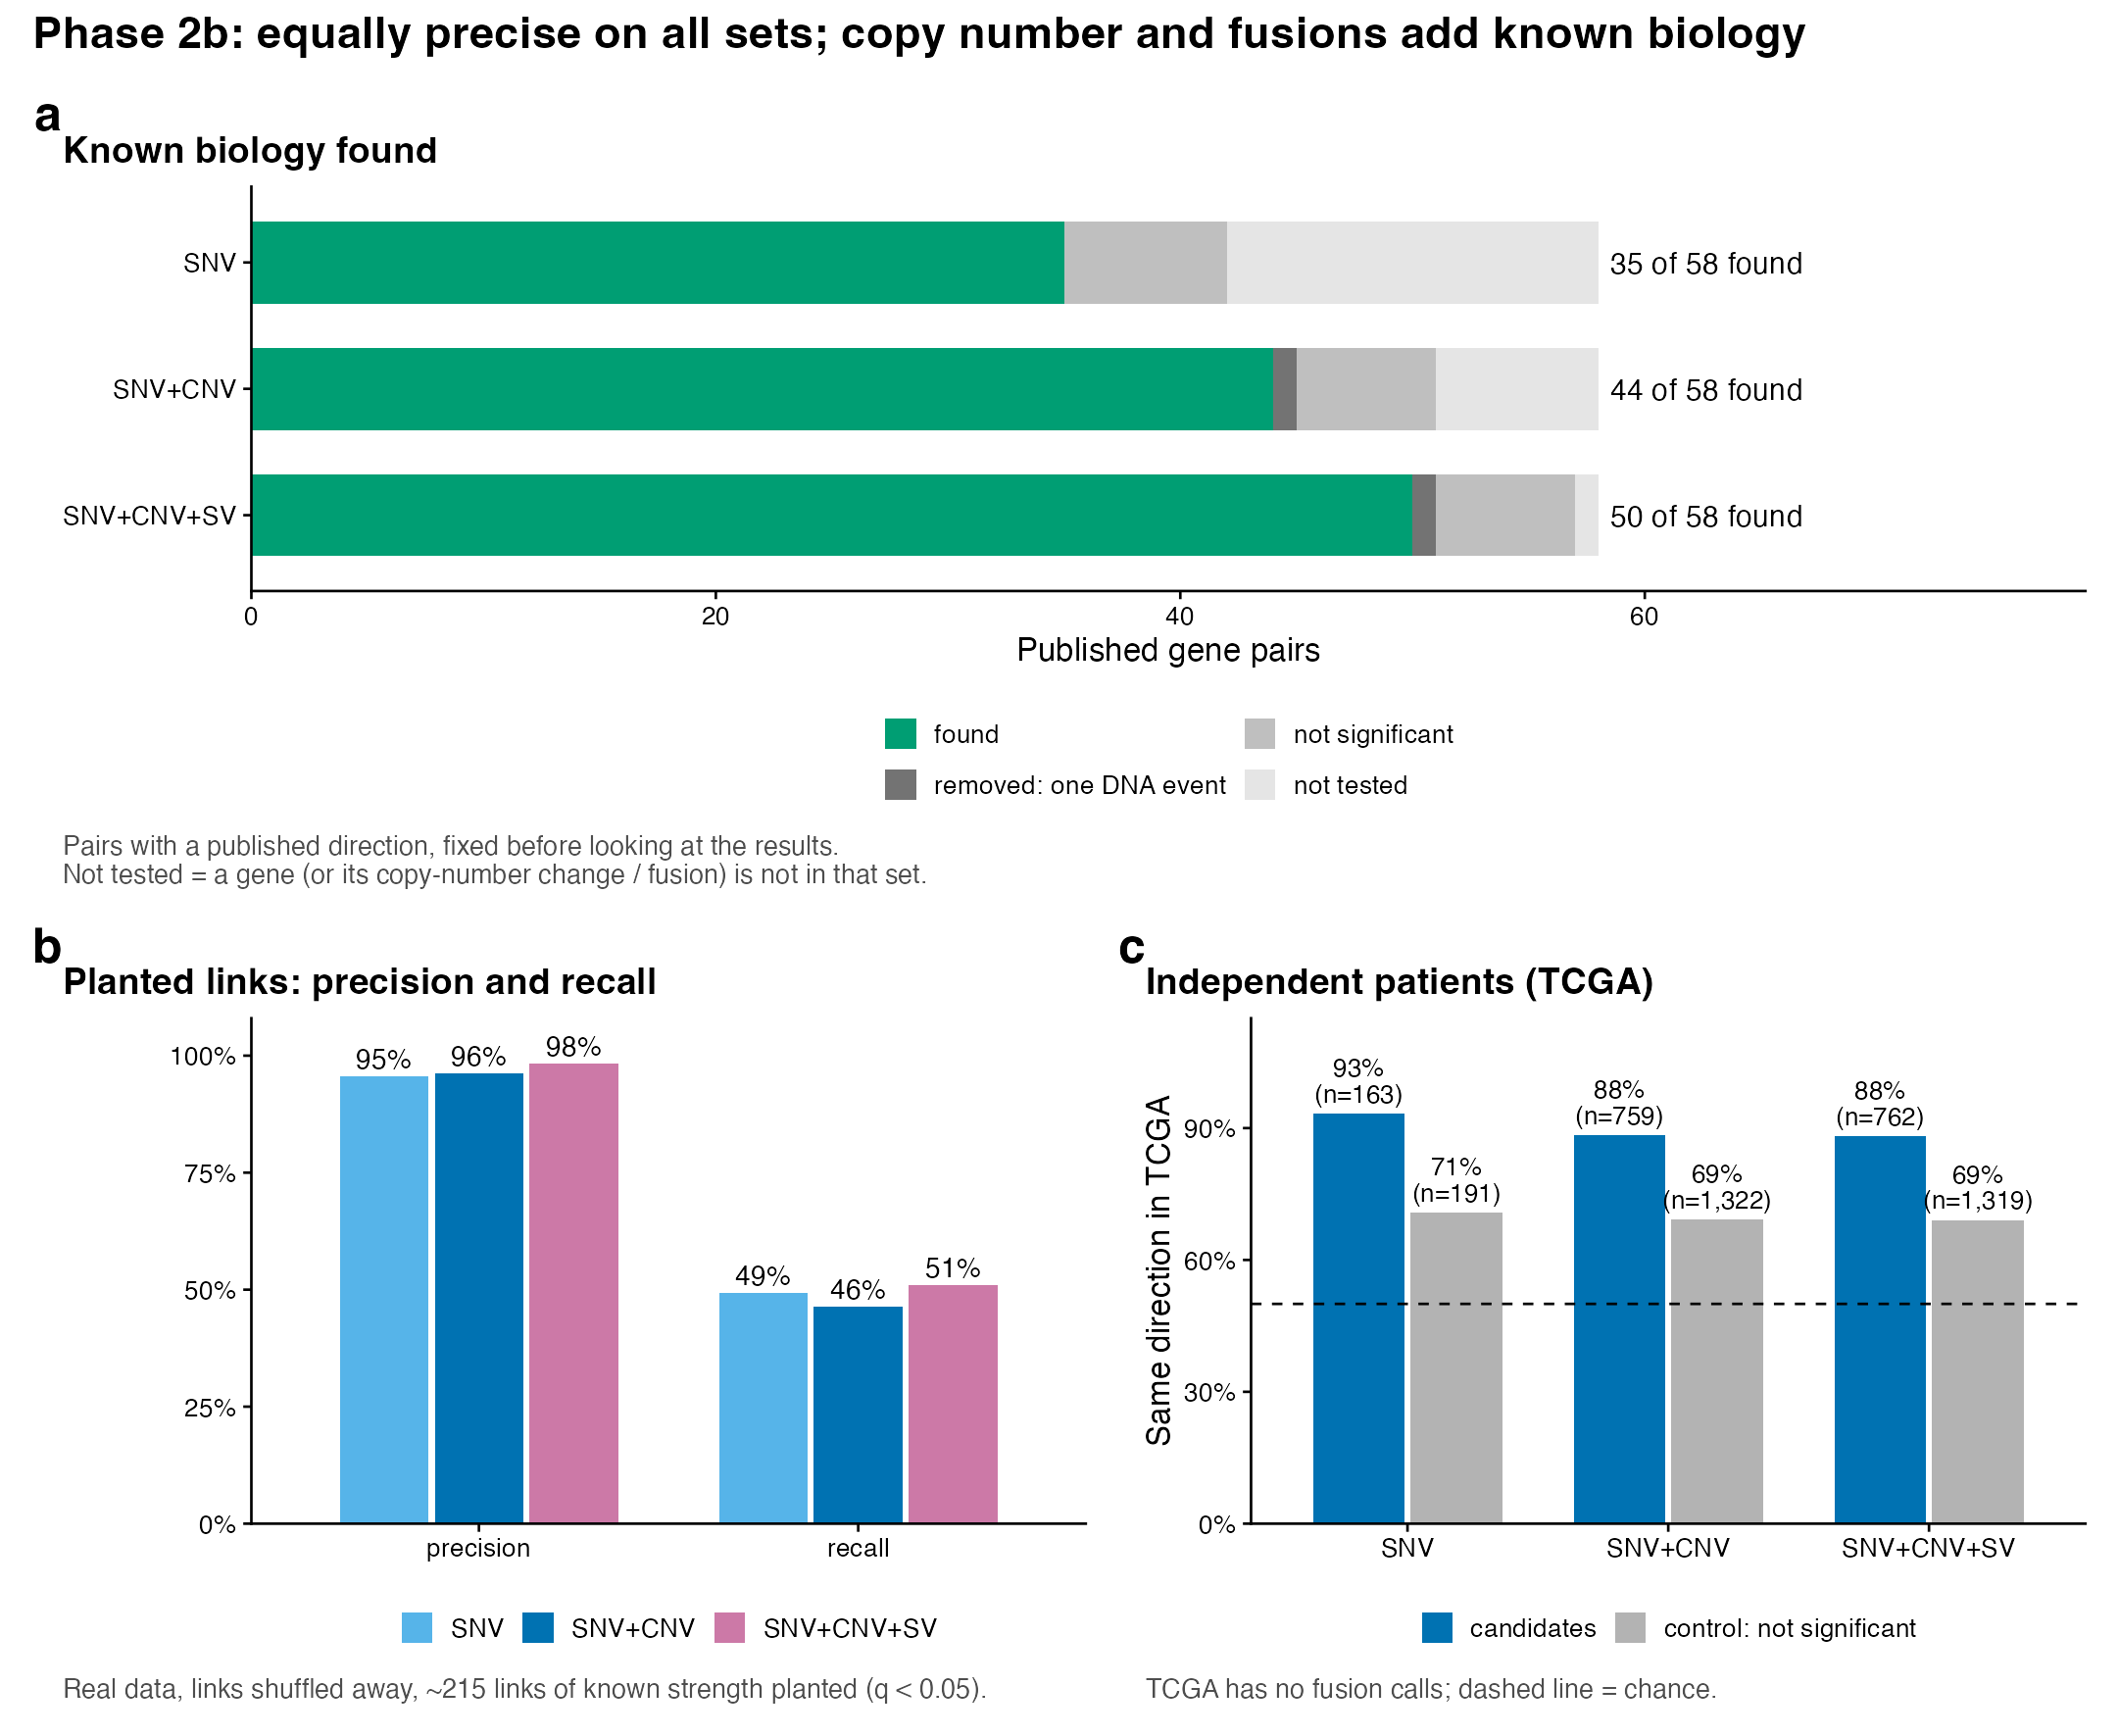

In [7]:
import subprocess, sys
from IPython.display import Image, display

# Rebuild this figure from the saved outputs: export small CSVs, then run the R script
subprocess.run([sys.executable, "scripts/figures/00_export_figure_data.py"], cwd="..", check=True, capture_output=True)
subprocess.run(["Rscript", "scripts/figures/phase2b_validation.R"], cwd="..", check=True, capture_output=True)
display(Image(filename="../results/figures/phase2b_validation/figure_phase2b.png", width=1000))

---
## Summary

| | SNV | **SNV+CNV (main)** | SNV+CNV+SV |
|---|---|---|---|
| Interaction candidates | 466 | **1,569** | 1,609 |
| Known pairs found (of 58) | 35 | **44** | 50 |
| Precision / recall (planted links) | 95% / 49% | **96% / 46%** | 98% / 51% |
| TCGA: same direction (control) | 93% (71%) | **88% (69%)** | 88% (69%) |
| Significant in the opposite direction (TCGA) | 0 | **0** | 0 |

1. **The test is equally precise on every set** -- the choice of set does not trade away trustworthiness.
2. **More alteration types find more known biology:** copy number adds 9 known pairs, fusions 6 more. The SNV set
   cannot see copy-number or fusion biology at all.
3. **SNV calls hold up slightly better in independent data**, because mutations are called more consistently than
   copy number.

So the main table is **SNV+CNV**: as precise as the others and it sees copy-number biology. Fusions (SNV+CNV+SV) add
the most known biology at no cost to precision; they stay a separate set until the supervisor decides whether fusions
belong in the main analysis.